### Desafio 1 - Deteccion temprana de renuncias en empresas de telecomunicaciones

- Nombre: Jose Ignacio Kuoman Jimenez
- Generacion: G76

#### Descripción

La oferta de servicios de telefonía ha ido en aumento en los últimos años, provocando una alta competencia que se traduce en menores precios y mejores prestaciones. Sin embargo, estas empresas luchan día a día por retener a sus clientes ya que el costo de un nuevo cliente es mayor que el de retener a un cliente antiguo. 

El objetivo de este desafío es entrenar un modelo de ensamble que permita predecir tempranamente si un cliente renunciará a la compañía, además de poder explicar cuál o cuáles son las características que más incidencia tienen en la separación de clientes con y sin renuncia. Para esto deberás aplicar los conceptos y herramientas aprendidas hasta ahora.

La muestra con la que se trabajará es un archivo llamado `telecom_churn.csv`, que contiene los siguientes atributos asociados a clientes:

1.	Churn (Variable objetivo): valor 1 si el cliente canceló el servicio, 0 si no 
2.	AccountWeeks: número de semanas que el cliente ha tenido activa la cuenta 
3.	ContractRenewal: toma el valor 1 si el cliente ha renovado recientemente el contrato, 0 en caso contrario 
4.	DataPlan: valor 1 si el cliente tiene plan de datos, 0 en caso contrario 
5.	DataUsage: Gigabytes de uso mensual de datos 
6.	CustServCalls: número de llamadas al servicio de atención al cliente 
7.	DayMins: promedio de minutos diurnos al mes 
8.	DayCalls: número medio de llamadas diurnas 
9.	MonthlyCharge: factura mensual media 
10.	OverageFee: mayor cuota de exceso en los últimos 12 meses 
11.	RoamMin: minutos de Roaming
e Roaming
e Roaming
 Roaming


Para lograr lo solicitado, debes realizar las siguientes tareas:

#### Pregunta 1

1. Importa las librerías necesarias y la base de datos, y realiza un análisis por variable usando visualizaciones. Debes considerar las posibles correlaciones y representarlas en un heatmap.

In [1]:
# Importar las bibliotecas necesarias

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, accuracy_score, classification_report
from sklearn.metrics import confusion_matrix

In [2]:
# Importamos la base de datos
df = pd.read_csv('telecom_churn.csv')

In [3]:
df.head()

,Churn,AccountWeeks,ContractRenewal,DataPlan,DataUsage,CustServCalls,DayMins,DayCalls,MonthlyCharge,OverageFee,RoamMins
0,0,128,1,1,2.7,1,265.1,110,89.0,9.87,10.0
1,0,107,1,1,3.7,1,161.6,123,82.0,9.78,13.7
2,0,137,1,0,0.0,0,243.4,114,52.0,6.06,12.2
3,0,84,0,0,0.0,2,299.4,71,57.0,3.10,6.6
4,0,75,0,0,0.0,3,166.7,113,41.0,7.42,10.1


Procedemos a analizar las variables

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3333 entries, 0 to 3332
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Churn            3333 non-null   int64  
 1   AccountWeeks     3333 non-null   int64  
 2   ContractRenewal  3333 non-null   int64  
 3   DataPlan         3333 non-null   int64  
 4   DataUsage        3333 non-null   float64
 5   CustServCalls    3333 non-null   int64  
 6   DayMins          3333 non-null   float64
 7   DayCalls         3333 non-null   int64  
 8   MonthlyCharge    3333 non-null   float64
 9   OverageFee       3333 non-null   float64
 10  RoamMins         3333 non-null   float64
dtypes: float64(5), int64(6)
memory usage: 286.6 KB


In [5]:
# Para hallar si hay valores nulos en los datos
df.isna().sum()

Churn              0
AccountWeeks       0
ContractRenewal    0
DataPlan           0
DataUsage          0
CustServCalls      0
DayMins            0
DayCalls           0
MonthlyCharge      0
OverageFee         0
RoamMins           0
dtype: int64

Podemos ver que no hay valores nulos en los datos.

Procedemos a hacer una analisis por variable usando visualizaciones

In [6]:
df.columns

Index(['Churn', 'AccountWeeks', 'ContractRenewal', 'DataPlan', 'DataUsage',
       'CustServCalls', 'DayMins', 'DayCalls', 'MonthlyCharge', 'OverageFee',
       'RoamMins'],
      dtype='object')

In [7]:
len(df.columns)

11

In [8]:
def representacion_de_las_variables(df):
    plt.figure(figsize = (13, 9))

    for idx, col in enumerate(df.columns):
        
        # La numeracion de los subplot comienza 1, por lo que se usa idx+1.
        # idx+1 ademas te va indicar en que columna estas
        plt.subplot(4, 3, idx+1)
        plt.title(col)
        plt.xlabel('')

        if len(df[col].unique()) > 2:
            sns.histplot(x=col, kde = True, data=df)

        else:
            sns.countplot(y=df[col])

        plt.tight_layout()

C:\Users\josek\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\Users\josek\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\Users\josek\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\Users\josek\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating

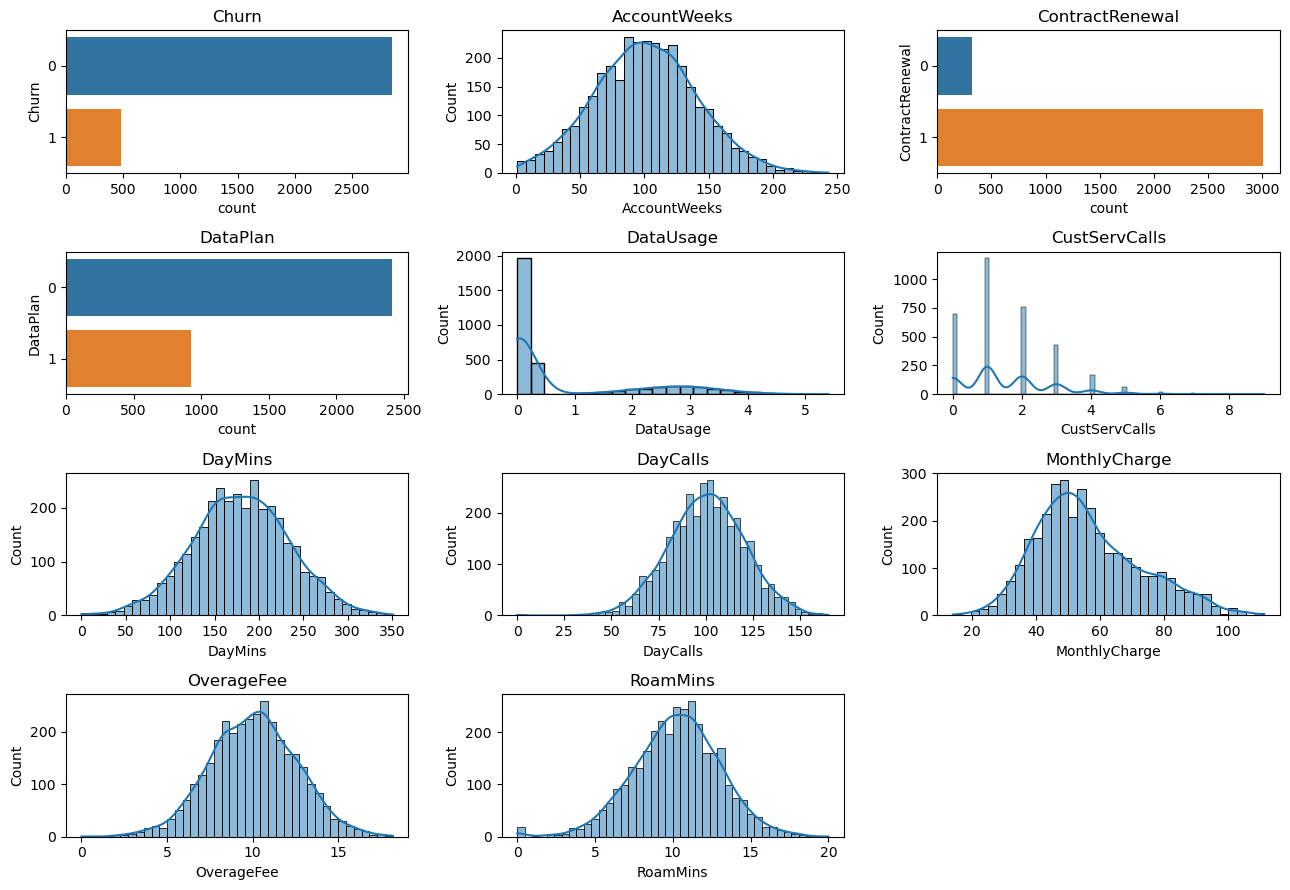

In [9]:
representacion_de_las_variables(df)

Vemos que hay 3 variables binarias:
- Churn
- ContractRenewal
- DataPlan

Vemos que hay 8 variables continuas:
- AccountWeeks
- DataUsage
- CustServCalls
- DayMins
- DayCalls
- MonthlyCharge
- OverageFee
- RoamMins

In [10]:
df.columns

Index(['Churn', 'AccountWeeks', 'ContractRenewal', 'DataPlan', 'DataUsage',
       'CustServCalls', 'DayMins', 'DayCalls', 'MonthlyCharge', 'OverageFee',
       'RoamMins'],
      dtype='object')

In [11]:
df.describe()

,Churn,AccountWeeks,ContractRenewal,DataPlan,DataUsage,CustServCalls,DayMins,DayCalls,MonthlyCharge,OverageFee,RoamMins
count,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000
mean,0.144914,101.064806,0.903090,0.276628,0.816475,1.562856,179.775098,100.435644,56.305161,10.051488,10.237294
std,0.352067,39.822106,0.295879,0.447398,1.272668,1.315491,54.467389,20.069084,16.426032,2.535712,2.791840
min,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,14.000000,0.000000,0.000000
25%,0.000000,74.000000,1.000000,0.000000,0.000000,1.000000,143.700000,87.000000,45.000000,8.330000,8.500000
50%,0.000000,101.000000,1.000000,0.000000,0.000000,1.000000,179.400000,101.000000,53.500000,10.070000,10.300000
75%,0.000000,127.000000,1.000000,1.000000,1.780000,2.000000,216.400000,114.000000,66.200000,11.770000,12.100000
max,1.000000,243.000000,1.000000,1.000000,5.400000,9.000000,350.800000,165.000000,111.300000,18.190000,20.000000


In [12]:
df['DataUsage'].value_counts()

DataUsage
0.00    1813
0.31      41
0.21      39
0.29      36
0.26      34
        ... 
5.40       1
4.40       1
4.73       1
4.64       1
0.68       1
Name: count, Length: 174, dtype: int64

In [13]:
df['CustServCalls'].value_counts()

CustServCalls
1    1181
2     759
0     697
3     429
4     166
5      66
6      22
7       9
9       2
8       2
Name: count, dtype: int64

#### Procedemos a ver ahora los outliers del conjunto de datos

Usamos una funcion para graficar los outliers de las variables continuas

In [14]:
# Funcion para revisar los outliers

def plot_boxplot_with_outliers(data, column_name, outlier_color = 'red', factor = 1.5):
    # Calcular los estadísticos clave
    Q1 = data[column_name].quantile(0.25)
    Q3 = data[column_name].quantile(0.75)
    IQR = Q3 - Q1

    # Calcular los límites para los valores atípicos
    lower_bound = Q1 - factor * IQR
    upper_bound = Q3 + factor * IQR
    
    # Crear un gráfico de diagrama de caja (boxplot)
    plt.figure(figsize=(8,10))
    sns.boxplot(y=data[column_name], showfliers=False)

    # plt.title(f'Diagrama de Caja de {column_name}')
    plt.ylabel(column_name)
    plt.xlabel(i)
    
    # Resaltar los valores atípicos en un color diferente
    outliers = data[(data[column_name] < lower_bound) | (data[column_name] > upper_bound)]
    plt.scatter(y=outliers[column_name], x=[0]*len(outliers), color=outlier_color, label='Outliers')

    # Anotar los valores de límites y cuartiles en el gráfico
    plt.text(0.35, Q1-0.55, f'Q1: {Q1:.2f}', fontsize=10)
    plt.text(0.35, Q3+0.3, f'Q3: {Q3:.2f}', fontsize=10)
    plt.text(0.205, lower_bound, f'Límite Inferior: {lower_bound:.2f}',fontsize=10)
    plt.text(0.205, upper_bound, f'Límite Superior: {upper_bound:.2f}',fontsize=10)
    plt.legend()
    plt.show()
    
    return outliers

#### Revisamos en primera instancia los outliers de las variables continuas

Recordar que habiamos determinado previamente cuales eran las variables continuas, siendo estas 8:
- AccountWeeks
- DataUsage
- CustServCalls
- DayMins
- DayCalls
- MonthlyCharge
- OverageFee
- RoamMins

In [15]:
df_var_cont = df[['AccountWeeks', 'DataUsage', 'CustServCalls', 'DayMins', 'DayCalls', 'MonthlyCharge', 'OverageFee', 'RoamMins']]
df_var_cont

,AccountWeeks,DataUsage,CustServCalls,DayMins,DayCalls,MonthlyCharge,OverageFee,RoamMins
0,128,2.70,1,265.1,110,89.0,9.87,10.0
1,107,3.70,1,161.6,123,82.0,9.78,13.7
2,137,0.00,0,243.4,114,52.0,6.06,12.2
3,84,0.00,2,299.4,71,57.0,3.10,6.6
4,75,0.00,3,166.7,113,41.0,7.42,10.1
...,...,...,...,...,...,...,...,...
3328,192,2.67,2,156.2,77,71.7,10.78,9.9
3329,68,0.34,3,231.1,57,56.4,7.67,9.6
3330,28,0.00,2,180.8,109,56.0,14.44,14.1
3331,184,0.00,2,213.8,105,50.0,7.98,5.0


<Figure size 200x100 with 0 Axes>

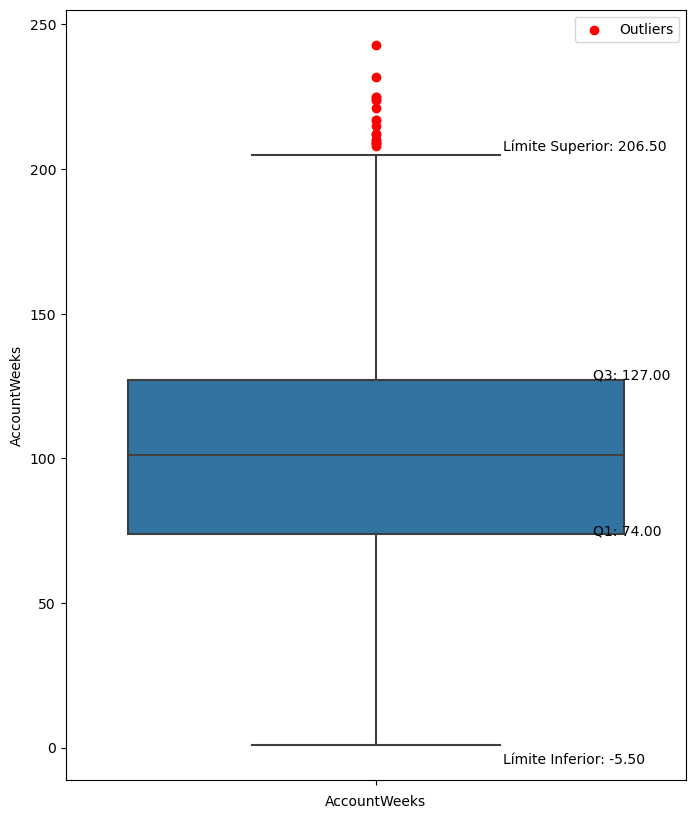

<Figure size 200x100 with 0 Axes>

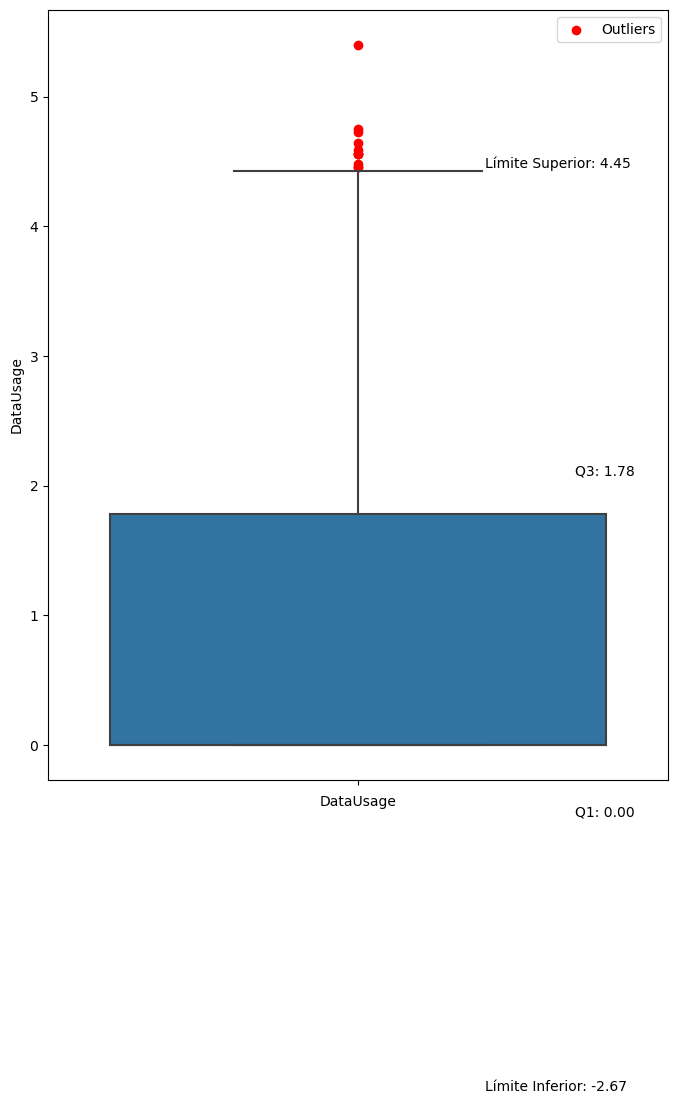

<Figure size 200x100 with 0 Axes>

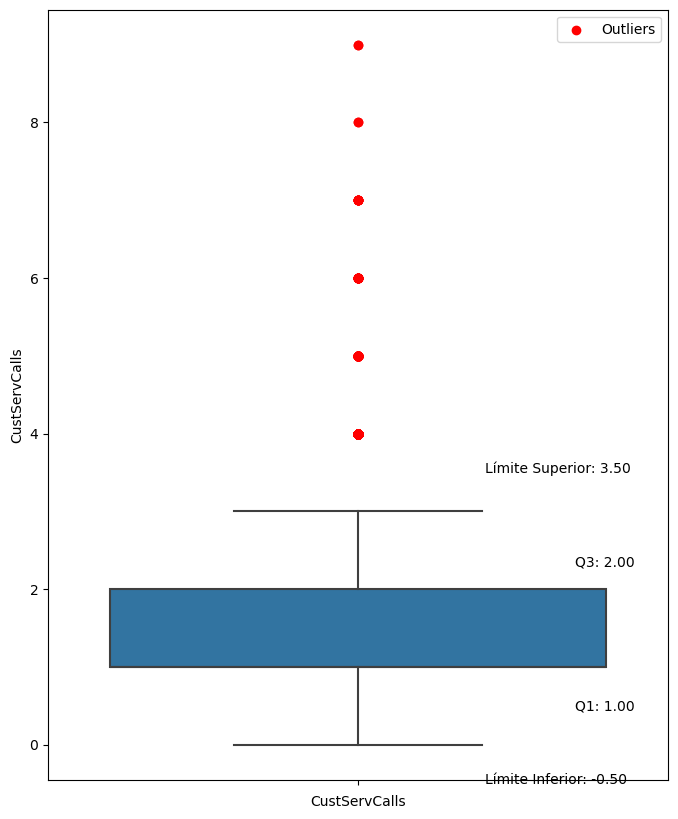

<Figure size 200x100 with 0 Axes>

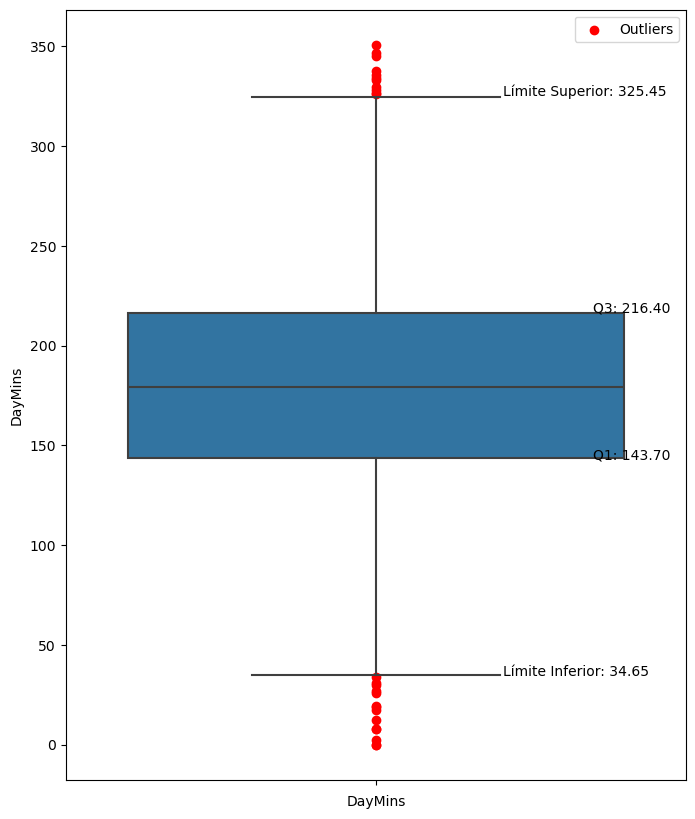

<Figure size 200x100 with 0 Axes>

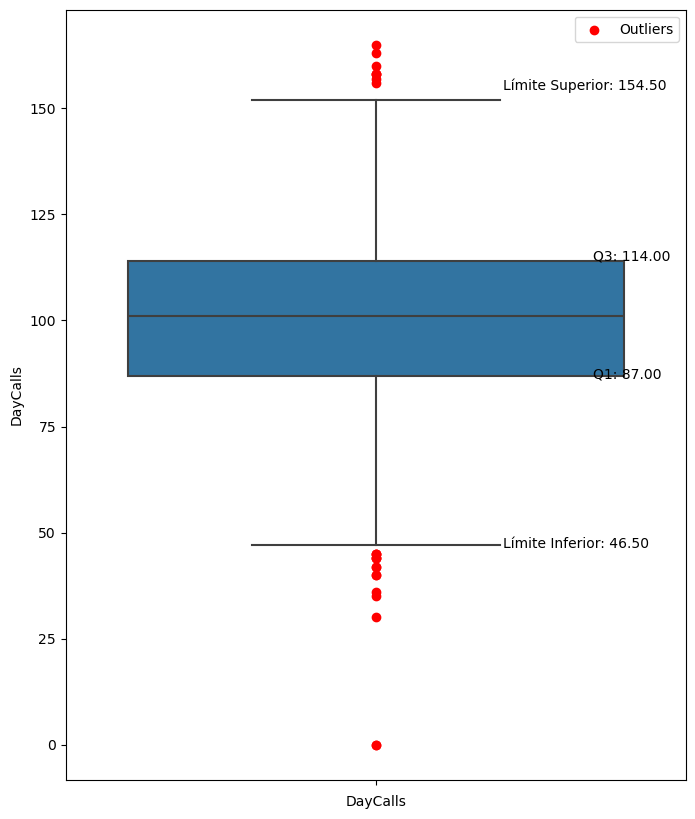

<Figure size 200x100 with 0 Axes>

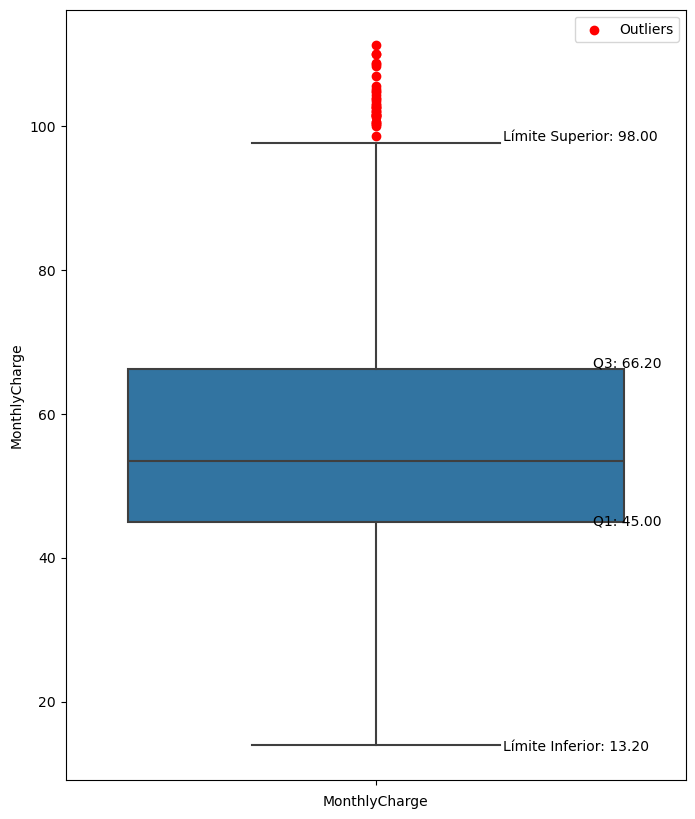

<Figure size 200x100 with 0 Axes>

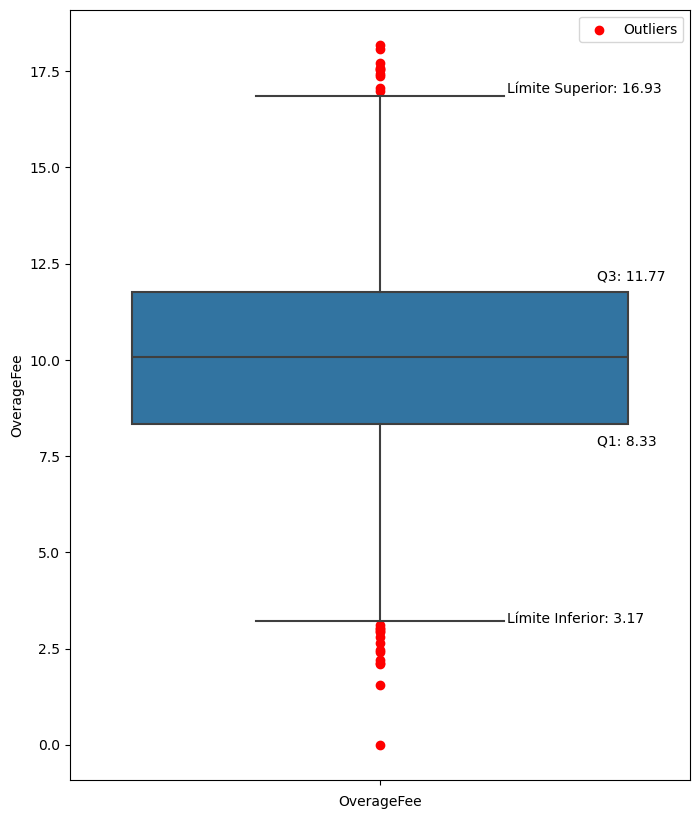

<Figure size 200x100 with 0 Axes>

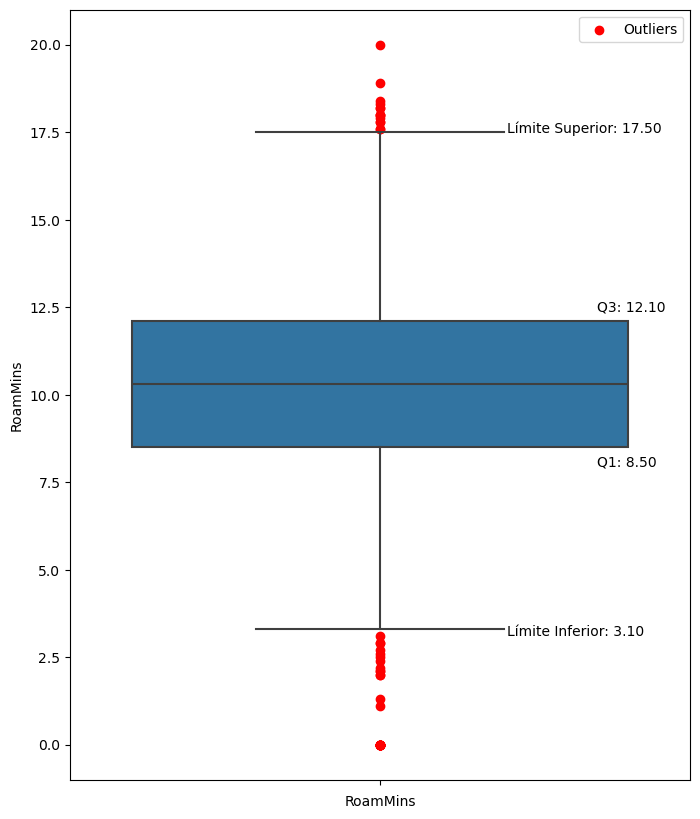

In [16]:
# Revision de los outliers de las variables continuas

for i in df_var_cont.columns:
    plt.figure(figsize=(2, 1))
    plot_boxplot_with_outliers(data = df, column_name = i, outlier_color = 'red', factor = 1.5)

In [17]:
df.shape

(3333, 11)

In [18]:
Q1 = df[['AccountWeeks', 'DataUsage', 'CustServCalls', 'DayMins', 'DayCalls', 'MonthlyCharge', 'OverageFee', 'RoamMins']].quantile(0.25)
Q3 = df[['AccountWeeks', 'DataUsage', 'CustServCalls', 'DayMins', 'DayCalls', 'MonthlyCharge', 'OverageFee', 'RoamMins']].quantile(0.75)
IQR = Q3 - Q1
# Recuento de outliers como recuento
((df[['AccountWeeks', 'DataUsage', 'CustServCalls', 'DayMins', 'DayCalls', 'MonthlyCharge', 'OverageFee', 'RoamMins']] < (Q1 - 1.5 * IQR)) | (df[['AccountWeeks', 'DataUsage', 'CustServCalls', 'DayMins', 'DayCalls', 'MonthlyCharge', 'OverageFee', 'RoamMins']] > (Q3 + 1.5 * IQR))).sum()

AccountWeeks      18
DataUsage         11
CustServCalls    267
DayMins           25
DayCalls          23
MonthlyCharge     34
OverageFee        24
RoamMins          46
dtype: int64

In [19]:
# Recuento de outliers como %
((df[['AccountWeeks', 'DataUsage', 'CustServCalls', 'DayMins', 'DayCalls', 'MonthlyCharge', 'OverageFee', 'RoamMins']] < (Q1 - 1.5 * IQR)) | (df[['AccountWeeks', 'DataUsage', 'CustServCalls', 'DayMins', 'DayCalls', 'MonthlyCharge', 'OverageFee', 'RoamMins']] > (Q3 + 1.5 * IQR))).mean()

AccountWeeks     0.005401
DataUsage        0.003300
CustServCalls    0.080108
DayMins          0.007501
DayCalls         0.006901
MonthlyCharge    0.010201
OverageFee       0.007201
RoamMins         0.013801
dtype: float64

Podemos ver que los outliers son significativos en la variable CustServCalls

#### Revisamos en segunda instancias los outliers de las variables binarias

Recordar que habiamos determinado previamente cuales eran las variables binarias, siendo estas 3:

- Churn
- ContractRenewal
- DataPlan

In [20]:
df['ContractRenewal'].value_counts()

ContractRenewal
1    3010
0     323
Name: count, dtype: int64

In [21]:
df['Churn'].value_counts()

Churn
0    2850
1     483
Name: count, dtype: int64

In [22]:
df2 = df.copy()

In [23]:
df2.head()

,Churn,AccountWeeks,ContractRenewal,DataPlan,DataUsage,CustServCalls,DayMins,DayCalls,MonthlyCharge,OverageFee,RoamMins
0,0,128,1,1,2.7,1,265.1,110,89.0,9.87,10.0
1,0,107,1,1,3.7,1,161.6,123,82.0,9.78,13.7
2,0,137,1,0,0.0,0,243.4,114,52.0,6.06,12.2
3,0,84,0,0,0.0,2,299.4,71,57.0,3.10,6.6
4,0,75,0,0,0.0,3,166.7,113,41.0,7.42,10.1


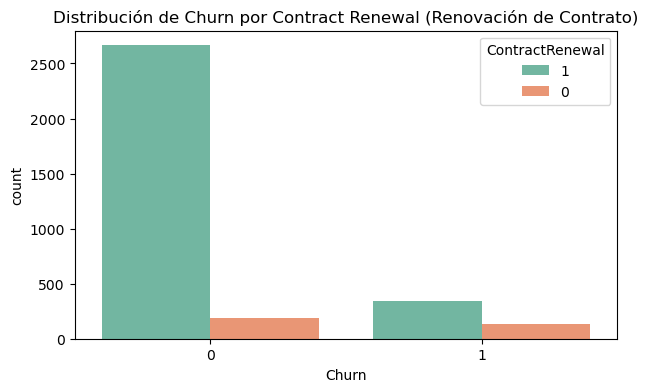

In [24]:
df2['Churn'] = df2['Churn'].astype(str)
df2['ContractRenewal'] = df2['ContractRenewal'].astype(str)

plt.figure(figsize=(7, 4))  # Ajustar el tamaño de la figura
sns.countplot(x='Churn', hue='ContractRenewal', data=df2, palette='Set2')
plt.title('Distribución de Churn por Contract Renewal (Renovación de Contrato)')
plt.show()

- Podemos ver que un gran cantiad de clientes ha renovado recientemente el servicio y que son muy pocos los clientes que no han renovao recientemente. (Churn = 0)
- Podemos ver que los han cancelado el servicio, también recientemente lo han renovado (Churn = 1)

In [25]:
df['Churn'].value_counts()

Churn
0    2850
1     483
Name: count, dtype: int64

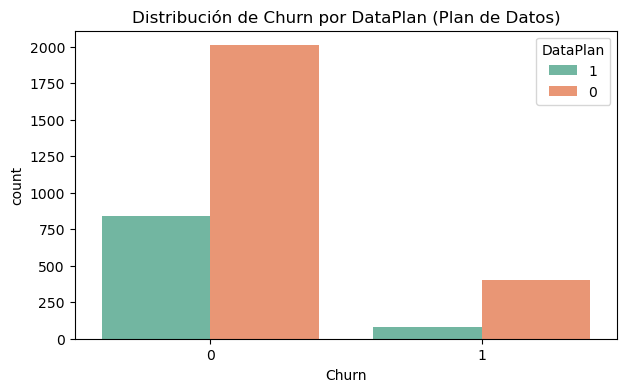

In [26]:
df2['DataPlan'] = df2['DataPlan'].astype(str)

plt.figure(figsize=(7, 4))  # Ajustar el tamaño de la figura
sns.countplot(x='Churn', hue='DataPlan', data=df2, palette='Set2')
plt.title('Distribución de Churn por DataPlan (Plan de Datos)')
plt.show()

- Podemos ver que la mayoría de clientes que no han cancelado el servicio no tiene un plan de datos.
- Por otro lado, la mayoría de clientes que no han renovado el servicio no tenían tampoco plan de datos.

Por lo cual, los planes de datos no son muy adquiridos por los clientes actuales y por los que dejaron de ser clientes.

#### Veamos ahora el nivel de asociación entre las variables

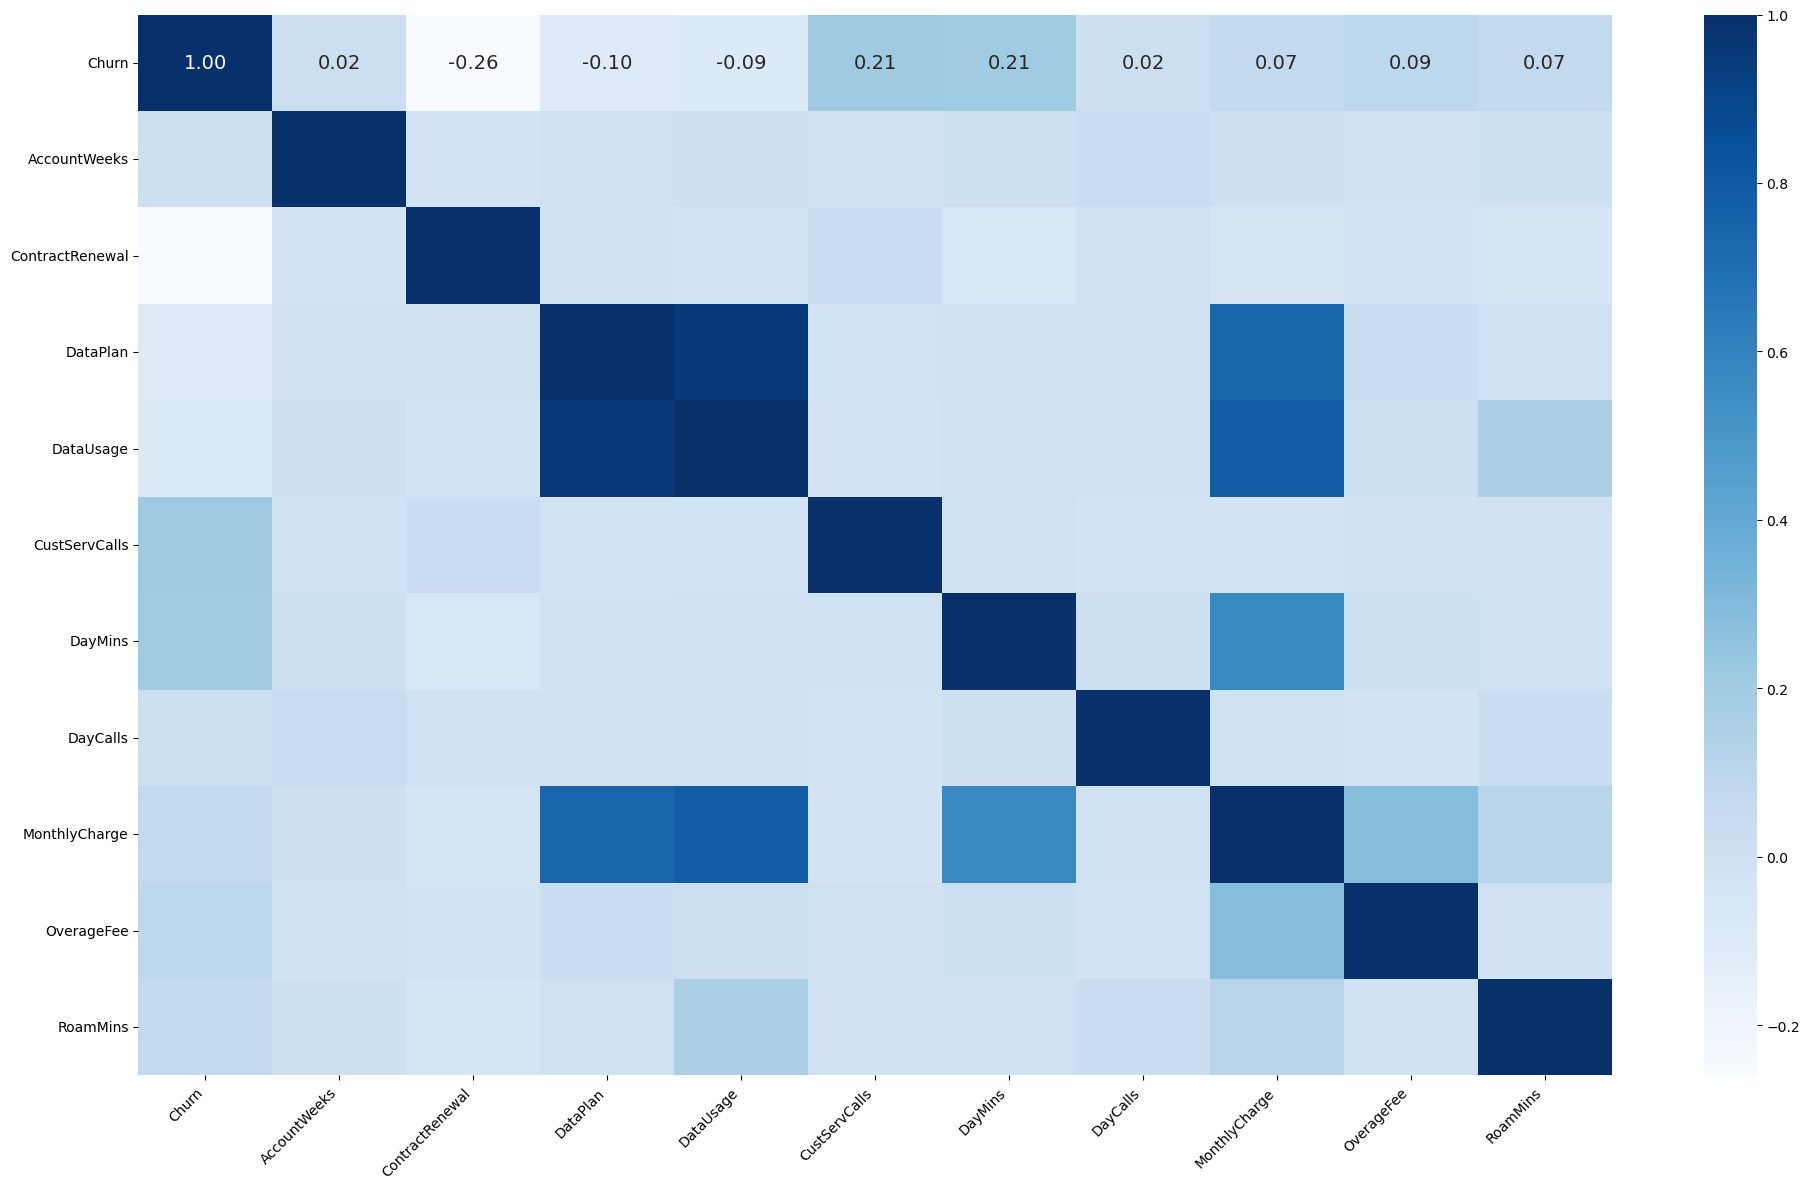

In [27]:
plt.figure(figsize=(20, 12))  # Aumentar el tamaño de la figura
sns.heatmap(df.corr(), cmap='Blues', annot=True, fmt='.2f' ,annot_kws={"size": 14});

# Rotar las etiquetas del eje x e y
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)

plt.tight_layout() # Ajusta automáticamente los márgenes
plt.show()

**A considerar**:

Se ha intentando etiquetar la asociacion de las variables pero no se ha podido en el heatmap. Por eso se realiza el siguiente codigo

In [28]:
# Como no se pudo hacer el heatmap se procedio a realizarlo de otra forma.

# Análisis de correlaciones
corr = df.corr()
corr.style.background_gradient(cmap='coolwarm')

,Churn,AccountWeeks,ContractRenewal,DataPlan,DataUsage,CustServCalls,DayMins,DayCalls,MonthlyCharge,OverageFee,RoamMins
Churn,1.000000,0.016541,-0.259852,-0.102148,-0.087195,0.208750,0.205151,0.018459,0.072313,0.092812,0.068239
AccountWeeks,0.016541,1.000000,-0.024735,0.002918,0.014391,-0.003796,0.006216,0.038470,0.012581,-0.006749,0.009514
ContractRenewal,-0.259852,-0.024735,1.000000,-0.006006,-0.019223,0.024522,-0.049396,-0.003755,-0.047291,-0.019105,-0.045871
DataPlan,-0.102148,0.002918,-0.006006,1.000000,0.945982,-0.017824,-0.001684,-0.011086,0.737490,0.021526,-0.001318
DataUsage,-0.087195,0.014391,-0.019223,0.945982,1.000000,-0.021723,0.003176,-0.007962,0.781660,0.019637,0.162746
CustServCalls,0.208750,-0.003796,0.024522,-0.017824,-0.021723,1.000000,-0.013423,-0.018942,-0.028017,-0.012964,-0.009640
DayMins,0.205151,0.006216,-0.049396,-0.001684,0.003176,-0.013423,1.000000,0.006750,0.567968,0.007038,-0.010155
DayCalls,0.018459,0.038470,-0.003755,-0.011086,-0.007962,-0.018942,0.006750,1.000000,-0.007963,-0.021449,0.021565
MonthlyCharge,0.072313,0.012581,-0.047291,0.737490,0.781660,-0.028017,0.567968,-0.007963,1.000000,0.281766,0.117433
OverageFee,0.092812,-0.006749,-0.019105,0.021526,0.019637,-0.012964,0.007038,-0.021449,0.281766,1.000000,-0.011023


Podemos ver en el grafico que existen varias variables independientes que se correlacionan significativamente.
- DataUsage con DataPlan
- MonthlyCharge con DataPlan, DataUsage y Daymins.

#### Pregunta 2

**2**. Desarrolla un modelo de árbol de decisión sin modificar sus hiper parámetros y despliega sus métricas de desempeño. Luego, mejora este modelo de forma de evitar el overfitting usando búsqueda por grilla con 5 kfold:
- max_depth: [5, 10, 15, 20, 25]
- min_samples_split: [0.01, 0.02, 0.03, 0.04]

Da a conocer los mejores hiper parámetros encontrados y el desempeño del modelo, tanto en los datos de entrenamiento como en los de test.

In [29]:
df.head()

,Churn,AccountWeeks,ContractRenewal,DataPlan,DataUsage,CustServCalls,DayMins,DayCalls,MonthlyCharge,OverageFee,RoamMins
0,0,128,1,1,2.7,1,265.1,110,89.0,9.87,10.0
1,0,107,1,1,3.7,1,161.6,123,82.0,9.78,13.7
2,0,137,1,0,0.0,0,243.4,114,52.0,6.06,12.2
3,0,84,0,0,0.0,2,299.4,71,57.0,3.10,6.6
4,0,75,0,0,0.0,3,166.7,113,41.0,7.42,10.1


In [30]:
# Separamos el conjunto de variables independientes y dependientes (objetivo)

X = df.loc[:, df.columns != 'Churn']
y = df['Churn']

In [31]:
# Importamos DecisionTreeClassifier
from sklearn.tree import DecisionTreeClassifier

# Separamos el conjunto de entrenamiento y de test
X_train, x_test, y_train, y_test = train_test_split(X, y, test_size = 0.3, random_state = 1234)

# Instanciamos DecisionTreeClassifier()
tree_cl = DecisionTreeClassifier()

# Entrenamos el modelo
tree_cl.fit(X_train, y_train)

# Estimamos las predicciones con el conjunto de entrenamiento
yhat_train = tree_cl.predict(X_train)

# Estimamos las predicciones con el conjunto de test
yhat_test = tree_cl.predict(x_test)

##### Evaluacion del rendimiento del modelo y de la clasificacion del conjunto de datos de entrenamiento

In [32]:
# Evaluamos el rendimiento del modelo en los datos de train
print('Accuracy: ', accuracy_score(y_train, yhat_train))
print('F1 Score: ', f1_score(y_train, yhat_train))

Accuracy:  1.0
F1 Score:  1.0


In [33]:
# Informe detallado de la clasificacion de los datos de train
print('\nInforme de clasificacion:')
print(classification_report(y_train, yhat_train))


Informe de clasificacion:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      2002
           1       1.00      1.00      1.00       331

    accuracy                           1.00      2333
   macro avg       1.00      1.00      1.00      2333
weighted avg       1.00      1.00      1.00      2333



##### Evaluacion del rendimiento del modelo y de la clasificacion del conjunto de datos de test

In [34]:
# Evaluamos el rendimiento del modelo en los datos de test
print('Accuracy: ', accuracy_score(y_test, yhat_test))
print('F1 Score: ', f1_score(y_test, yhat_test))

Accuracy:  0.885
F1 Score:  0.6525679758308157


In [35]:
# Informe detallado de la clasificacion de los datos de test
print('\nInforme de clasificacion:')
print(classification_report(y_test, yhat_test))


Informe de clasificacion:
              precision    recall  f1-score   support

           0       0.95      0.92      0.93       848
           1       0.60      0.71      0.65       152

    accuracy                           0.89      1000
   macro avg       0.77      0.81      0.79      1000
weighted avg       0.89      0.89      0.89      1000



Procedemos ahora a mejorar el modelo con la finalidad de evitar el overfitting usando búsqueda por grilla con 5 kfold:
- max_depth: [5, 10, 15, 20, 25]
- min_samples_split: [0.01, 0.02, 0.03, 0.04]

In [36]:
grid_search = GridSearchCV(tree_cl,
                           {'max_depth': [5, 10, 15, 20, 25],
                            'min_samples_split': [0.01, 0.02, 0.03, 0.04]}, 
                           n_jobs=10, 
                           cv = 5)

grid_search.fit(X_train, y_train)

GridSearchCV(cv=5, estimator=DecisionTreeClassifier(), n_jobs=10,
             param_grid={'max_depth': [5, 10, 15, 20, 25],
                         'min_samples_split': [0.01, 0.02, 0.03, 0.04]})

In [37]:
grid_search.best_estimator_

DecisionTreeClassifier(max_depth=10, min_samples_split=0.02)

In [38]:
# Mostrar la combinación óptima de hiperparámetros encontrados
print("Hiperparámetros óptimos:")
print(grid_search.best_params_)

Hiperparámetros óptimos:
{'max_depth': 10, 'min_samples_split': 0.02}


##### Desempeño del modelo en los datos de entrenamiento

In [39]:
# Desempeño del modelo en los datos de entrenamiento

# Estimamos las predicciones con el conjunto de entrenamiento
yhat_train = grid_search.predict(X_train)

confusion_matrix(yhat_train, y_train)

array([[1964,  109],
       [  38,  222]], dtype=int64)

In [40]:
# Evaluamos el rendimiento del modelo en los datos de train
print('Accuracy: ', accuracy_score(y_train, yhat_train))
print('F1 Score: ', f1_score(y_train, yhat_train))

Accuracy:  0.936990998714102
F1 Score:  0.751269035532995


In [41]:
# Informe detallado de la clasificacion de los datos de train
print('\nInforme de clasificacion:')
print(classification_report(y_train, yhat_train))


Informe de clasificacion:
              precision    recall  f1-score   support

           0       0.95      0.98      0.96      2002
           1       0.85      0.67      0.75       331

    accuracy                           0.94      2333
   macro avg       0.90      0.83      0.86      2333
weighted avg       0.93      0.94      0.93      2333



##### Desempeño del modelo en los datos de test

In [42]:
# Desempeño del modelo en los datos de test

# Estimamos las predicciones con el conjunto de entrenamiento
yhat_test = grid_search.predict(x_test)

confusion_matrix(yhat_test, y_test)

array([[827,  42],
       [ 21, 110]], dtype=int64)

In [43]:
# Evaluamos el rendimiento del modelo en los datos de test
print('Accuracy: ', accuracy_score(y_test, yhat_test))
print('F1 Score: ', f1_score(y_test, yhat_test))

Accuracy:  0.937
F1 Score:  0.7773851590106007


In [44]:
# Informe detallado de la clasificacion de los datos de test
print('\nInforme de clasificacion:')
print(classification_report(y_test, yhat_test))


Informe de clasificacion:
              precision    recall  f1-score   support

           0       0.95      0.98      0.96       848
           1       0.84      0.72      0.78       152

    accuracy                           0.94      1000
   macro avg       0.90      0.85      0.87      1000
weighted avg       0.93      0.94      0.94      1000



Podemos ver que el desempeño del modelo del conjunto test usando una búsqueda con grilla con 5kfold, se ha podido evitar el sobre ajuste y, asimismo, el modelo ha logrado un muy desempeño mejor que el del entrenamiento.

#### Pregunta 3

3. Balancea las clases usando SMOTE para el conjunto de entrenamiento. Luego, aplica un modelo de Bagging con 200 estimadores y muestra las métricas sobre el conjunto de test.


##### Procedemos en primera instancia a balancear las clases usando SMOTE para el conjunto de entrenamiento

In [45]:
# Procedemos a ver el conjunto de entrenamineto de y para ver las diferencias de clases.

y_train.value_counts()

Churn
0    2002
1     331
Name: count, dtype: int64

Si vemos tenemos una mayor proporcion de datos 0, que los de 1. Por lo cual, usaremos SMOTE para equilibrar los datos.

##### Aplicación de Smote

In [46]:
# Aplicamos SMOTE para balancear las clases en el conjunto de entrenamiento

from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state = 1234)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

# Vemos la cantidad de clases despues de aplicar SMOTE
print(f"Distribución de clases antes de SMOTE: {y_train.value_counts()}\n")
print(f"Distribución de clases después de SMOTE: {y_train_smote.value_counts()}")

Distribución de clases antes de SMOTE: Churn
0    2002
1     331
Name: count, dtype: int64

Distribución de clases después de SMOTE: Churn
0    2002
1    2002
Name: count, dtype: int64


##### Procedemos ahora a aplicar un modelo Bagging con 200 estimadores

In [47]:
# Importamos la libreria BaggingClassifier

from sklearn.ensemble import BaggingClassifier

In [48]:
# Entrenar un modelo de Bagging con 200 estimadores (usando árboles de decisión como base)

# Instanciamos DecisionTreeClassifier()
tree_cl = DecisionTreeClassifier()

# Procedemos a hacer el modelo BaggingClassifier con 200 estimadores
bagging_cl = BaggingClassifier(estimator=tree_cl, n_estimators=200, random_state=1234)

# Procedemos a entrenar el modelo con el conjunto de entrenamiento balanceado
bagging_cl.fit(X_train_smote, y_train_smote)

# Prediccion para conjunto de test
yhat_test = bagging_cl.predict(x_test)


##### Mostramos las métricas sobre el conjunto de test

In [49]:
# Mostrar las métricas de evaluación
print("Matriz de confusión:")
print(confusion_matrix(y_test, yhat_test), '\n')

print(f"Accuracy: {accuracy_score(y_test, yhat_test):.4f}")
print(f"F1 Score: {f1_score(y_test, yhat_test):.4f}")

Matriz de confusión:
[[790  58]
 [ 25 127]] 

Accuracy: 0.9170
F1 Score: 0.7537


In [50]:
print("\nReporte de clasificación:")
print(classification_report(y_test, yhat_test))


Reporte de clasificación:
              precision    recall  f1-score   support

           0       0.97      0.93      0.95       848
           1       0.69      0.84      0.75       152

    accuracy                           0.92      1000
   macro avg       0.83      0.88      0.85      1000
weighted avg       0.93      0.92      0.92      1000



Podemos ver que el modelo Bagging ha tenido un buen desempeño, sin embargo, el modelo visto previamente de la **Pregunta 1**, el cual utiliza el conjunto test usando grilla con 5 kfold lo supera por un poco en cuanto a sus métricas.

#### Pregunta 4

4.	Implementa un modelo de Bagging usando modelos heterogéneos con los siguientes estimadores: Regresión Logística, Árbol de decisión, y dos SVM de clasificación con kernel ‘rbf’ y ‘sigmoid’. Para ello considera 200 muestras bootstrap (T). 

Debes calibrar la importancia de los modelos, repitiendo el modelo que sea más importante en la lista de modelos a entrenar. Considera que un mejor modelo es aquel con mejor f1-score. Muestra las métricas del modelo final aplicado al conjunto de test. (Para realizar esta tarea utiliza la función bagging_het que se encuentra en el archivo util_bagging.p
.py)T).t.

##### a. En primera instancia evaluamos que modelo tiene el mejor f1-score

Importamos las librerias que vamos a necesitar para desarrollar los 4 modelos: Regresion Logistica, Arbol de decision y 2 SVM de clasificacion con kernel rbg y sigmoid

In [51]:
# Necitaremos estandarizar los datos
from sklearn.preprocessing import StandardScaler

# Importamos la libreria para desarrollar los modelos de Regresion Logistica y SVM
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC

Estandarizamos los datos

In [52]:
# Ya tenemos dividido el conjunto de prueba y de entrenamiento

# Debido a que los algoritmos SVM y de Regresion Logistica son sensibles a la escala de los datos, necesitamos estandarizar las características usando StandardScaler()
scaler = StandardScaler()
X_train_std = scaler.fit_transform(X_train)
X_test_std = scaler.transform(x_test)

**A considerar**

Los modelos que si requieren estandarizacion de datos son los siguientes:
- Regresion Logistica
- Maquinas de Soporte Vectorial (SVM)
- Redes Neuronales
- K-Nearest Neighbors (KNN)

Por lo cual, se estandarizara los datos para aplicarlos en el Modelo de Regresion Logistica y en los 2 modelos SVM.
Sin embargo, también en este caso se hará con el Árbol de decisión con la finalidad de que todos los modelos usen los mismos datos. Es más que todo por simplificación

##### Modelo de Regresion Logistica

In [53]:
# instanciamos el modelo de Regresion Logistica
model_lr = LogisticRegression(random_state=1234)

# Entrenamos el modelo
model_lr.fit(X_train_std, y_train)

LogisticRegression(random_state=1234)

In [54]:
# Predecimos las etiquetas de la variable objetivo para el conjunto de prueba
y_pred_lr = model_lr.predict(X_test_std)

# Determinamos el f1-score
print(f"F1 Score: {f1_score(y_test, y_pred_lr):.4f}")

F1 Score: 0.2316


##### Modelo de Arbol de decision

In [55]:
# instanciamos el modelo de DecisionTreeClassifier

model_dtc = DecisionTreeClassifier(random_state=1234)

# Entrenamos el modelo
model_dtc.fit(X_train_std, y_train)

DecisionTreeClassifier(random_state=1234)

In [56]:
# Predecimos las etiquetas de la variable objetivo para el conjunto de prueba
y_pred_dtc = model_dtc.predict(X_test_std)

# Determinamos el f1-score
print(f"F1 Score: {f1_score(y_test, y_pred_dtc):.4f}")

F1 Score: 0.6422


##### Modelo SVM con Kernel rbf

In [57]:
# instanciamos el SVC con Kernel rbg
svm_rbf = SVC(kernel='rbf', random_state= 1234)

# Entrenamos el modelo
svm_rbf.fit(X_train_std, y_train)

SVC(random_state=1234)

In [58]:
# Evaluamos el f1-score
y_pred_rbf = svm_rbf.predict(X_test_std)

# Determinamos el f1-score
print(f"F1 Score: {f1_score(y_test, y_pred_rbf):.4f}")

F1 Score: 0.6777


##### Modelo SVM con Kernel sigmoid

In [59]:
# instanciamos el SVC con Kernel sigmoid
svm_sigmoid = SVC(kernel='sigmoid', random_state= 1234)

# Entrenamos el modelo
svm_sigmoid.fit(X_train_std, y_train)

SVC(kernel='sigmoid', random_state=1234)

In [60]:
# Evaluamos el f1-score
y_pred_sigmoid = svm_sigmoid.predict(X_test_std)

# Determinamos el f1-score
print(f"F1 Score: {f1_score(y_test, y_pred_sigmoid):.4f}")

F1 Score: 0.1506


##### Evalucion del mejor F1 Score:

- Modelo de Regresion Logistica -> F1 Score: 0.2316
- Modelo de Arbol de Decision -> F1 Score: 0.6442
- Modelo SVM de clasificacion con kernel 'rbf' -> F1 Score: 0.6777
- Modelo SVM de clasificacion con kernel 'sigmoid' -> F1 Score: 0.1506

Por lo cual, vemos que el mejor modelo vendria a ser el modelo SVM de clasificacion con Kernel rbf al tener el F1 Score mas elevado, siendo este igual a 0.6777

b. Repetimos el modelo más importante, en este caso el que tiene el mejor F1-score, más veces en el modelo Bagging.

c. Implementamos el modelo Bagging utilizando 200 muestras bootstrap (T = 200)

d. Mostramos las métricas del modelo final aplicado al conjunto 
de test. 

#### Pregunta 5

5.	Implementa un modelo de ensamble Random Forest usando como hiper parámetro n_estimators = 45. El modelo debe usar muestra OOB para estimar su ajuste ACCURACY, y debe mostrar las cuatro características más importantes junto con las métricas de desempeño en el conjunto de test.

In [61]:
# Configuramos el modelo Random Forest con n_estimators=45 y OOB

rf_clf = RandomForestClassifier(n_estimators=45, oob_score=True, random_state=1234)

# Procedemos a entrenar el modelo con el conjunto de entrenamiento
rf_clf.fit(X_train, y_train)

# Estimación de r^2 con datos OOB
rf_clf.oob_score_

# prediccion para el conjunto de test
yhat_test = rf_clf.predict(x_test)

##### Mostramos las métricas de desempeño en el conjunto de test

In [62]:
# Mostramos las métricas de evaluación
print("Matriz de confusión:")
print(confusion_matrix(y_test, yhat_test), '\n')

print(f"Accuracy: {accuracy_score(y_test, yhat_test):.4f}")
print(f"F1 Score: {f1_score(y_test, yhat_test):.4f}")

Matriz de confusión:
[[834  14]
 [ 37 115]] 

Accuracy: 0.9490
F1 Score: 0.8185


In [63]:
print("\nReporte de clasificación:\n")
print(classification_report(y_test, yhat_test))


Reporte de clasificación:

              precision    recall  f1-score   support

           0       0.96      0.98      0.97       848
           1       0.89      0.76      0.82       152

    accuracy                           0.95      1000
   macro avg       0.92      0.87      0.89      1000
weighted avg       0.95      0.95      0.95      1000



Podemos ver que usando una tecnica de RandomForestClassifier, se pudo lograr un excelente desempeño al tener un Accuracy mayor a 0.9 y un F1 Score mayor a 0.8.

##### Desarrollo para mostrar las 4 caracteristicas más importantes del modelo

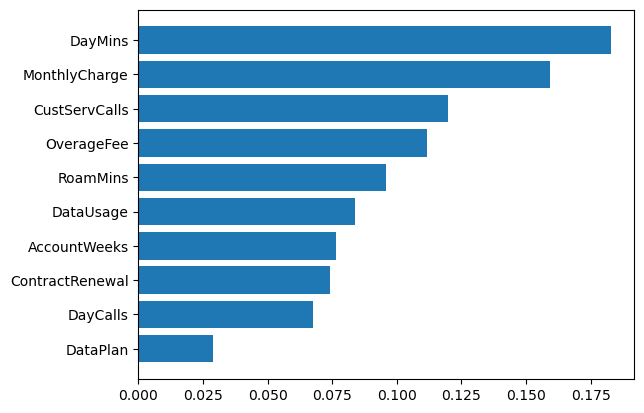

In [64]:
# visualizar importancia de los atributos del modelo

# Obtener los índices ordenados de las importancias
idx_sort = np.argsort(rf_clf.feature_importances_)

# Graficar las caracteristicas
plt.barh(y=rf_clf.feature_names_in_[idx_sort], width=rf_clf.feature_importances_[idx_sort]);

##### Mostramos solamente las 4 caracteristicas mas importantes

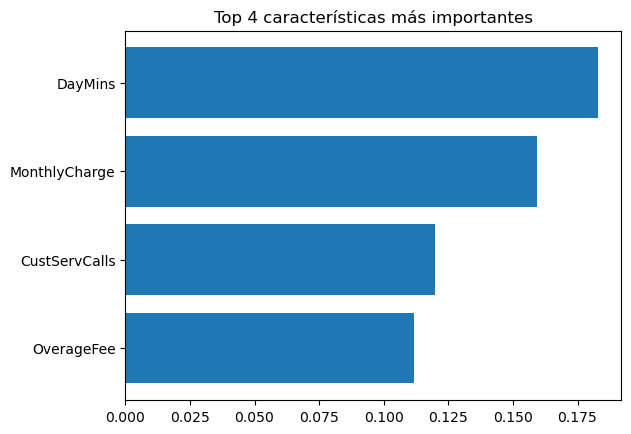

In [65]:
# Seleccionamos solamente las 4 características más importantes (las últimas 4 en idx_sort)
top_4_idx = idx_sort[-4:]

# Graficamos solamente las 4 características más importantes
plt.barh(y=rf_clf.feature_names_in_[top_4_idx], width=rf_clf.feature_importances_[top_4_idx])
plt.title('Top 4 características más importantes')
plt.show()

##### Otra manera de mostramos las 4 caracteristicas más importante, pero de forma más detallada

In [66]:
# datos con la importancia de cada variable
importances = rf_clf.feature_importances_

# nombre de las variables
feature_names = X.columns

In [67]:
# Generamos un DataFrame
importance_df = pd.DataFrame({'Feature': feature_names, 'Importance': importances})

# Ordenamos el DataFrame
importance_df = importance_df.sort_values(by='Importance', ascending=False)

In [68]:
importance_df.head()

,Feature,Importance
5,DayMins,0.182820
7,MonthlyCharge,0.159247
4,CustServCalls,0.119978
8,OverageFee,0.111726
9,RoamMins,0.095713


In [69]:
# Mostramos las 4 características más importantes
print("\nLas 4 características más importantes:\n")
importance_df.head(4)


Las 4 características más importantes:



,Feature,Importance
5,DayMins,0.182820
7,MonthlyCharge,0.159247
4,CustServCalls,0.119978
8,OverageFee,0.111726


Visualizamos las 4 caracteristicas mas importantes en grafico usando el DataFrame que hemos generado recientemente importance_df

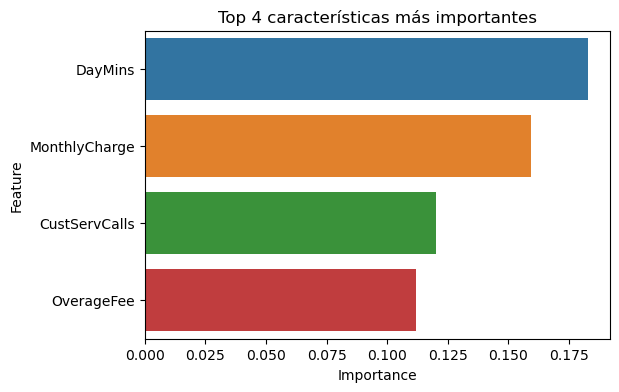

In [70]:
# Usamos el DataFrame importance_df

plt.figure(figsize=(6, 4))
sns.barplot(x='Importance', y='Feature', data=importance_df.head(4))
plt.title('Top 4 características más importantes')
plt.show()

##### Pregunta 6

6.	Realiza una búsqueda de grilla para un modelo Random Forest para los siguientes rangos de valores para sus hiper parámetros:
    - n_estimators: 50 - 200 con paso de 10 completando 15 valores
    - max_features: [‘sqrt’, ‘log2’, None]



Muestra los mejores hiper parámetros encontrados, la estimación de desempeño en los datos OOB, y despliega los cuatro atributos más importantes. ¿Tienen sentido estos? Analiza además las métricas de desempeño, ROC y AUC.


In [71]:
param_grid = {
    'n_estimators': np.arange(50, 201, 10)[:15],
    'max_features': ['sqrt', 'log2', None]
}

In [72]:
grid_model6 = GridSearchCV(
    RandomForestClassifier(oob_score=True, random_state=1234),
    param_grid=param_grid,
    n_jobs=-1
)

grid_model6.fit(X_train, y_train)

GridSearchCV(estimator=RandomForestClassifier(oob_score=True,
                                              random_state=1234),
             n_jobs=-1,
             param_grid={'max_features': ['sqrt', 'log2', None],
                         'n_estimators': array([ 50,  60,  70,  80,  90, 100, 110, 120, 130, 140, 150, 160, 170,
       180, 190])})

In [73]:
grid_model6.best_estimator_

RandomForestClassifier(n_estimators=130, oob_score=True, random_state=1234)

#### Mejores hiper parámetros encontrados

In [74]:
print('\n---')
print('Mejores valores de hiper parámetros encontrados:')
print(grid_model6.best_params_)
print('---\n')


---
Mejores valores de hiper parámetros encontrados:
{'max_features': 'sqrt', 'n_estimators': 130}
---



In [75]:
# obtenemos el mejor modelo
best_rf_clf_model = grid_model6.best_estimator_

# Realizar predicciones en el conjunto de prueba
yhat_test = best_rf_clf_model.predict(x_test)

##### Medición de r2 desde datos OOB

In [76]:
best_rf_clf_model.oob_score_

0.9241320188598371

##### Mostramos las métricas de desempeño en el conjunto de test

In [77]:
# Mostramos las métricas de evaluación
print("Matriz de confusión:")
print(confusion_matrix(y_test, yhat_test), '\n')

print(f"Accuracy: {accuracy_score(y_test, yhat_test):.4f}")
print(f"F1 Score: {f1_score(y_test, yhat_test):.4f}")

Matriz de confusión:
[[838  10]
 [ 38 114]] 

Accuracy: 0.9520
F1 Score: 0.8261


In [78]:
print("\nReporte de clasificación:\n")
print(classification_report(y_test, yhat_test))


Reporte de clasificación:

              precision    recall  f1-score   support

           0       0.96      0.99      0.97       848
           1       0.92      0.75      0.83       152

    accuracy                           0.95      1000
   macro avg       0.94      0.87      0.90      1000
weighted avg       0.95      0.95      0.95      1000



Podemos ver que tenemos un muy buen modelo de Random Forest al tener métricas con muy buen desempeño.

##### Desarrollo para mostrar los 4 atributos más importantes.

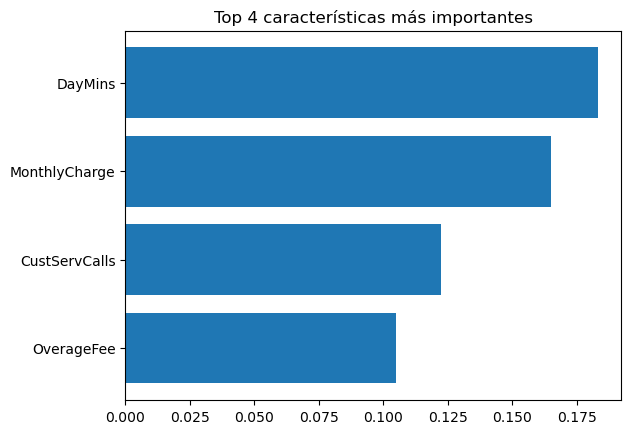

In [79]:
# Obtener los índices ordenados de las importancias
idx_sort = np.argsort(best_rf_clf_model.feature_importances_)

# Seleccionamos solamente las 4 características más importantes (las últimas 4 en idx_sort)
top_4_idx = idx_sort[-4:]

# Graficamos solamente las 4 características más importantes
plt.barh(y=best_rf_clf_model.feature_names_in_[top_4_idx], width=best_rf_clf_model.feature_importances_[top_4_idx])
plt.title('Top 4 características más importantes')
plt.show()

##### Analisis de ROC y AUC

In [80]:
# Importamos la libreria para hacer desarrollar el ROC y AUC
from sklearn.metrics import roc_curve, roc_auc_score

Predecimos las probabilidades para el conjunto de test (para clase 1)

In [81]:
# Para realizar la curva, necesitamos calcular las probabilidades de cada una de las observaciones.
# Por lo cual, predecimos las probabilidades para el conjunto de test (para la clase 1)
# Recordar que clase 1 viene a significar que el cliente ha cancelado el servicio.

yhat_roc = best_rf_clf_model.predict_proba(x_test)[:, 1]


Calculamos la curva ROC

In [82]:
# Falsos positivos -> false_positive
# Verdaderos positivos -> true_positive
# threshold -> umbral de decisión
false_positive, true_positive, threshold = roc_curve(y_test, yhat_roc)

Calculamos el AUC

In [83]:
auc = roc_auc_score(y_test, yhat_roc)
print(f"AUC: {auc:.3f}")

AUC: 0.929


El AUC al ser superior a 0.9, indica un buen desempeño.

Procedemos a graficar la curva ROC

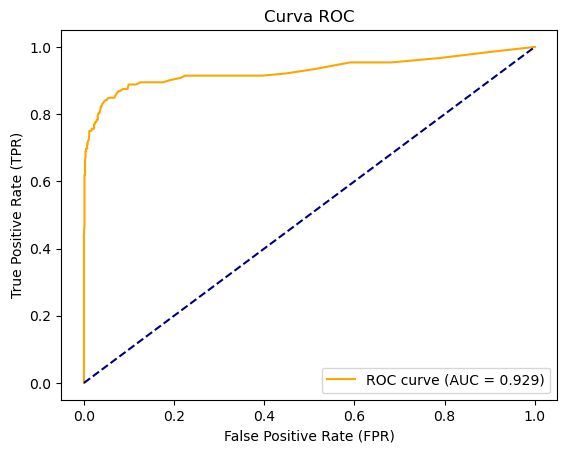

In [84]:
plt.figure()
plt.plot(false_positive, true_positive, color='orange', label=f'ROC curve (AUC = {auc:.3f})')
plt.plot([0, 1], [0, 1], color='navy', linestyle='--')  # Línea de referencia
plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')
plt.title('Curva ROC')
plt.legend(loc="lower right")
plt.show()

##### Pregunta 7

7.	Usando el modelo Random Forest con sus hiper parámetros ajustados, muestre los 15 clientes que presentan la mayor propensión a renunciar.

##### Recordar lo siguiente sobre la variable objetivo

- Churn (Variable objetivo): valor 1 si el cliente canceló el servicio, 0 si no

##### Para resolver la pregunta 7 realizaremos 3 pasos con las siguientes secuencias: **a, b y c**

a. Obtener las probabilidades de que cada persona en el conjunto de prueba tenga cáncer maligno

In [85]:
# Recordar que ya se han calculado las probabilidades para el conjunto de test (para la clase 1), es decir, para los clientes
# que han cancelado el servicio

# Se hizo en el Analisis de ROC y AUC

# yhat_roc = best_rf_clf_model.predict_proba(x_test)[:, 1]

b. Procedemos a extraer esas probabilidades, colocarlas en un DataFrame y ordenarlas de mayor a menor.

In [86]:
# Por lo cual extraemos las probabilidades de cancelacion del servicio y lo colocamos en un DataFrame
df_probabilidad = pd.DataFrame({'Probabilidad_de_cancelacion_de_servicio': yhat_roc, 'Prueba_real': y_test})

# Procedemos a ordenar las probabilidades de haber cancelado el servicio de mayor a menor
df_probabilidad_ordenado = df_probabilidad.sort_values(by = 'Probabilidad_de_cancelacion_de_servicio', ascending = False)

c. Mostramos los 15 clientes que presentan la mayor propension a renunciar

In [87]:
df_top_15 = df_probabilidad_ordenado.head(15)

In [88]:
df_top_15

,Probabilidad_de_cancelacion_de_servicio,Prueba_real
3205,0.992308,1
2708,0.984615,1
2573,0.984615,1
3132,0.976923,1
2099,0.976923,1
2536,0.976923,1
2647,0.969231,1
3079,0.961538,1
21,0.961538,1
1405,0.946154,1


Podemos ver que los clientes que presentan la mayor propension a renunciar son los que tiene los índices de la tabla.